<img src="https://devra.ai/analyst/notebook/2997/image.jpg" style="width: 100%; height: auto;" />

<div style="text-align:center; border-radius:15px; padding:15px; color:white; margin:0; font-family: 'Orbitron', sans-serif; background: #2E0249; background: #11001C; box-shadow: 0px 4px 8px rgba(0, 0, 0, 0.3); overflow:hidden; margin-bottom: 1em;">    <div style="font-size:150%; color:#FEE100"><b>Adult Income Prediction Analysis with Logistic Regression</b></div>    <div>This notebook was created with the help of <a href="https://devra.ai/ref/kaggle" style="color:#6666FF">Devra AI</a></div></div>Welcome to an exploration of the Adult Income Prediction dataset. Although income might not buy happiness, it can certainly provide insights into valuable socioeconomic trends. If you find this notebook useful, please consider upvoting it.

## Table of Contents1. [Imports and Configuration](#Imports-and-Configuration)2. [Data Import](#Data-Import)3. [Data Cleaning and Preprocessing](#Data-Cleaning-and-Preprocessing)4. [Exploratory Data Analysis](#Exploratory-Data-Analysis)5. [Feature Engineering](#Feature-Engineering)6. [Predictor Building](#Predictor-Building)7. [Conclusions and Future Work](#Conclusions-and-Future-Work)

In [1]:
# Suppress warnings for cleaner output
import warnings
warnings.simplefilter('ignore')

# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')  # Ensure compatibility in non-interactive environments
import matplotlib.pyplot as plt
plt.switch_backend('Agg')  # If only plt is used
%matplotlib inline
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, auc

# Set visualization style
sns.set(style='whitegrid')

In [2]:
# Data Importprint('Loading the Adult Income Prediction dataset...')
data_path = '/kaggle/input/adult-income-prediction-dataset/adult.csv'
df = pd.read_csv(data_path, delimiter=',', encoding='ascii')

# Display basic information about the dataset
print('Dataset shape:', df.shape)
print('Columns:', list(df.columns))

Dataset shape: (32561, 15)
Columns: ['age', 'workclass', 'fnlwgt', 'education', 'education.num', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'capital.gain', 'capital.loss', 'hours.per.week', 'native.country', 'income']


In [3]:
# Data Cleaning and Preprocessing# Note: The dataset does not contain any explicit date fields, so no date parsing is required.print('Checking for missing values...')
missing = df.isnull().sum()
print(missing[missing > 0])

# Sometimes string fields contain extra spaces; let's strip them
for col in df.select_dtypes(include=['object']).columns:
    df[col] = df[col].str.strip()

print('Data cleaning complete.')

Series([], dtype: int64)
Data cleaning complete.


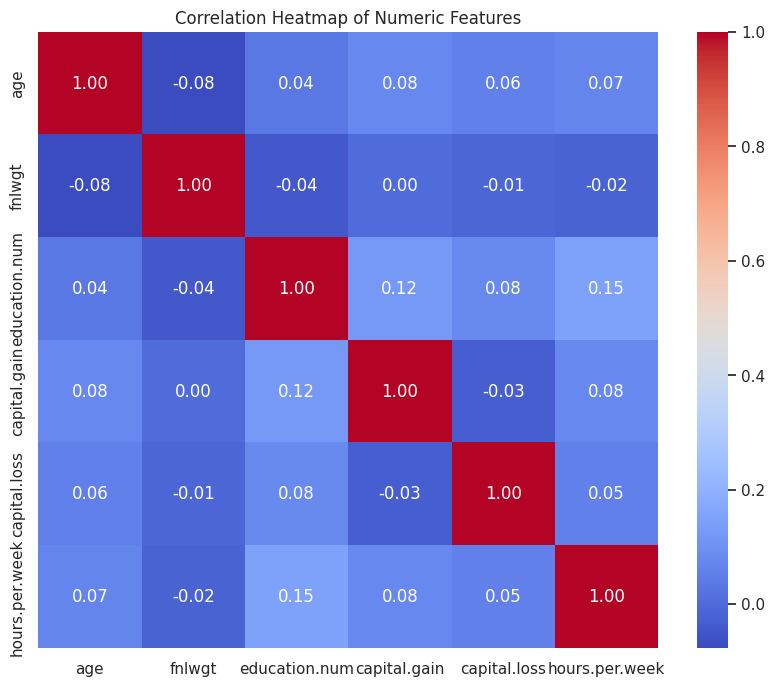

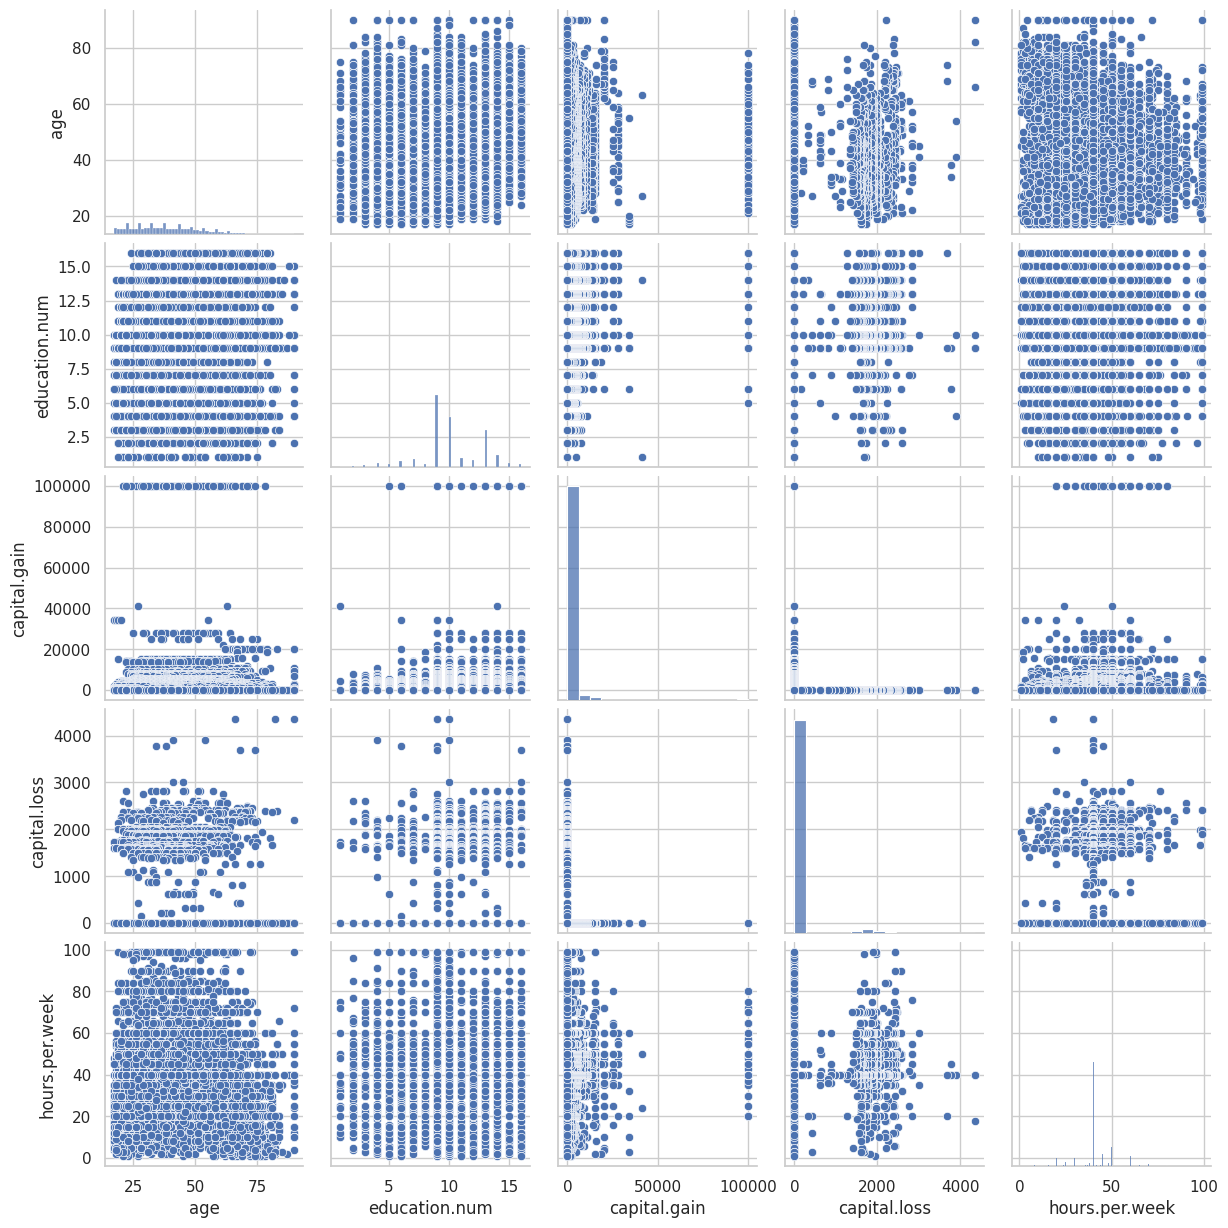

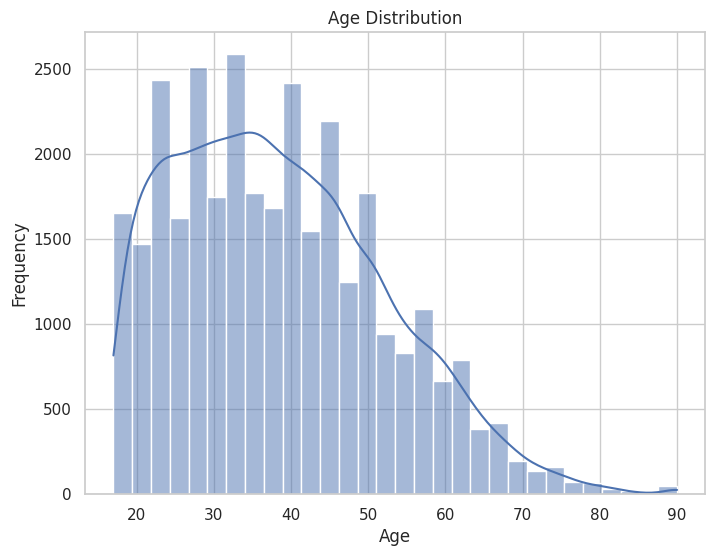

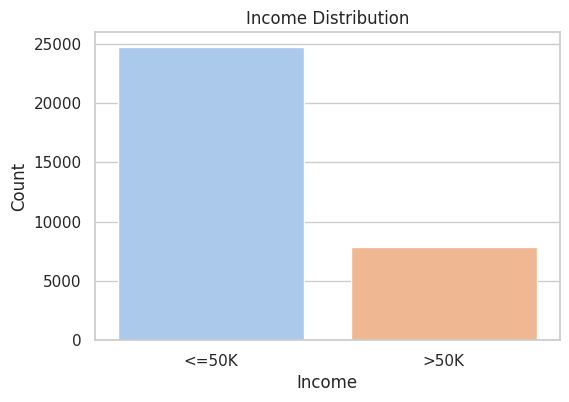

In [4]:
# Exploratory Data Analysisprint('Performing exploratory data analysis...')

# Correlation heatmap among numeric features (only if 4 or more numeric columns exist)
numeric_df = df.select_dtypes(include=[np.number])
if numeric_df.shape[1] >= 4:
    plt.figure(figsize=(10, 8))
    correlation = numeric_df.corr()
    sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')
    plt.title('Correlation Heatmap of Numeric Features')
    plt.show()
else:
    print('Insufficient numeric columns for a correlation heatmap.')

# Pair plot among a subset of numeric features
selected_features = ['age', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week']
if all(feat in numeric_df.columns for feat in selected_features):
    sns.pairplot(df[selected_features])
    plt.show()

# Histogram for 'age'
plt.figure(figsize=(8, 6))
sns.histplot(df['age'], bins=30, kde=True)
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

# Count plot (Pie Chart alternative) for income distribution
plt.figure(figsize=(6, 4))
sns.countplot(x='income', data=df, palette='pastel')
plt.title('Income Distribution')
plt.xlabel('Income')
plt.ylabel('Count')
plt.show()

In [5]:
# Feature Engineering# Create a binary target column for income (>50K as 1, <=50K as 0)
df['income_bin'] = df['income'].apply(lambda x: 1 if '>50K' in x else 0)

# Quick sanity check on the new target variable
print('Value counts for income_bin:')
print(df['income_bin'].value_counts())

Value counts for income_bin:
income_bin
0    24720
1     7841
Name: count, dtype: int64


Prediction Accuracy: 0.8474


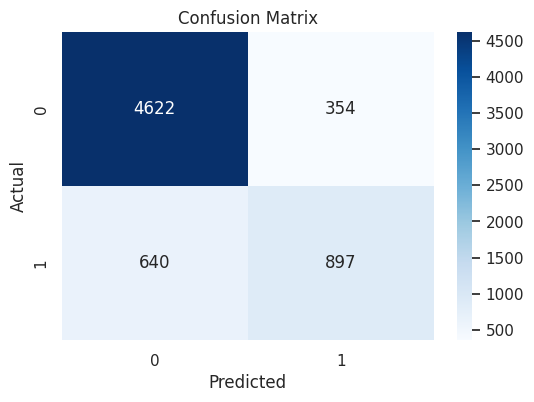

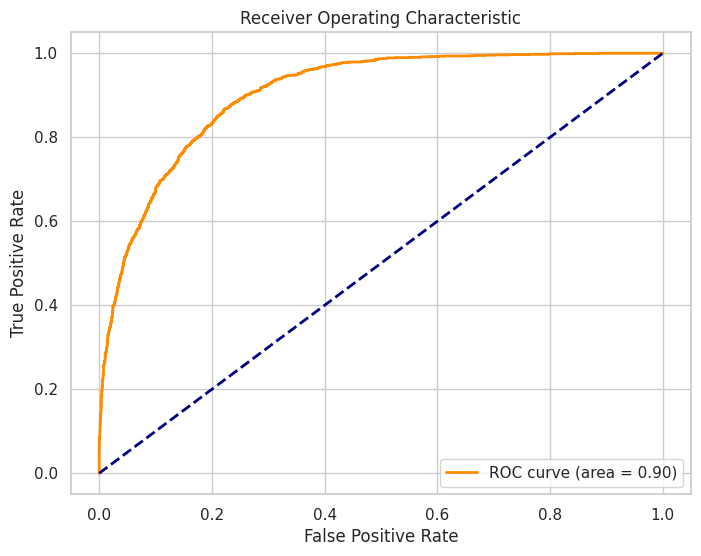

2025-09-13 04:53:12.486985: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1757739192.762853      13 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1757739192.834291      13 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


Permutation Feature Importances (top 10):
                             feature    weight       std
0                      education.num  0.033379  0.002224
1                       capital.gain  0.029050  0.002264
2  marital.status_Married-civ-spouse  0.027453  0.003162
3         occupation_Exec-managerial  0.007984  0.001450
4          occupation_Prof-specialty  0.007523  0.001511
5                  relationship_Wife  0.007155  0.001156
6                       capital.loss  0.003593  0.001105
7                           sex_Male  0.003286  0.000587
8                                age  0.003040  0.002566
9             relationship_Own-child  0.002487  0.001171


In [6]:
# Predictor Buildingprint('Building and evaluating the logistic regression model...')

# Separating features and target variable
X = df.drop(columns=['income', 'income_bin'])
y = df['income_bin']

# One-hot encoding for categorical variables
categorical_cols = X.select_dtypes(include=['object']).columns
X = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

# Scaling numeric features to facilitate model convergence
scaler = StandardScaler()
numeric_cols = X.select_dtypes(include=[np.number]).columns
X[numeric_cols] = scaler.fit_transform(X[numeric_cols])

# Splitting the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Building the logistic regression model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# Predicting on the test set
y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print(f'Prediction Accuracy: {acc:.4f}')

# Displaying the confusion matrix using a heatmap
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Plotting the ROC curve
y_pred_proba = model.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc='lower right')
plt.show()

# Optionally compute permutation feature importances
# Note: The eli5 package is used for this purpose. However, some users have encountered compatibility issues
try:
    import eli5
    from eli5.sklearn import PermutationImportance

    perm = PermutationImportance(model, random_state=42).fit(X_test, y_test)
    feature_importances = eli5.format_as_dataframe(eli5.explain_weights(perm, feature_names=X_test.columns.tolist()))

    print('Permutation Feature Importances (top 10):')
    print(feature_importances.head(10))
except ImportError as e:
    print('Warning: eli5 package is not installed or not compatible with the current environment.')
    print('To compute permutation importances, please install eli5 using: pip install eli5')
except Exception as e:
    print('An error occurred while computing permutation feature importances:')
    print(e)

# End of model building section

## Conclusions and Future WorkThis notebook has demonstrated several aspects of the Adult Income Prediction dataset analysis, from basic exploratory data analysis and visualization to building a logistic regression predictor for income classification. The approach taken here includes:
- Data cleaning and careful preprocessing (including handling of potential issues like extra whitespace).
- Use of visualizations (heatmaps, pair plots, histograms, and confusion matrices) to better understand the data distribution and relationships.
- Model construction with a predictor evaluation that includes both accuracy and ROC curve analysis.
- An optional step to compute permutation feature importances, which can be invaluable in understanding feature contributions. Users should note the potential compatibility issues with the eli5 library and adjust their environment accordingly.

For future analysis, one could consider:
- Trying more sophisticated models such as Random Forests or Gradient Boosting.
- Incorporating cross-validation to further evaluate model performance.
- Delving into more refined feature engineering to capture nonlinear relationships or interactions between features.

If you found this notebook useful, please consider upvoting it.